# Multi-task learning for HAR: UCI-HAR demo

Walks through the pipeline in `har_mtl/`: load data, train the multi-task model
(signal reconstruction + classification), evaluate on unseen subjects.
Run this notebook from the `notebooks/` folder after `pip install -r requirements.txt`.

In [1]:
import sys
sys.path.insert(0, "..")  # make the har_mtl package importable

import numpy as np

from har_mtl.data import load_uci_har
from har_mtl.evaluation import plot_confusion_matrix, predict_labels, report
from har_mtl.models import HParams
from har_mtl.training import train

## 1. Data
Downloads UCI-HAR into `../data` on first use.

In [2]:
dataset = load_uci_har("../data")
{k: v["data"].shape for k, v in dataset.items() if k != "labels"}

{'train': (5881, 128, 10),
 'validation': (1471, 128, 10),
 'test': (2947, 128, 10)}

## 2. Train
`mode` can be `MTL` (proposed), `classifier` (supervised baseline) or `AE` (unsupervised baseline).

In [11]:
hp = HParams(epochs=10)  # increase epochs for better results
model, history = train(dataset, hp, mode="MTL")

Shape the data (5881, 128, 10) (5881, 6) (1471, 128, 10) (1471, 6)


Model: "mtl_model_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ encoder (Functional)                 │ ?                           │          17,730 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ classifier (Functional)              │ ?                           │             206 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ decoder (Functional)                 │ ?                           │          20,930 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 38,866 (151.82 KB)

 Trainable params: 38,786 (151.51 KB)

 Non-trainable params: 80 (320.00 B)

Epoch 1/10
(None, 128, 10) (None, 6)
(None, 128, 10) (None, 6)
45/46 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5097 - loss: 5.9402 - rmse: 0.7834(None, 128, 10) (None, 6)
46/46 ━━━━━━━━━━━━━━━━━━━━ 34s 103ms/step - accuracy: 0.5179 - loss: 5.8975 - rmse: 0.7821 - val_accuracy: 0.8783 - val_loss: 3.5921 - val_rmse: 0.7191
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9072 - loss: 3.2440 - rmse: 0.7156 - val_accuracy: 0.9415 - val_loss: 2.3422 - val_rmse: 0.6576
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.9389 - loss: 2.1504 - rmse: 0.6579 - val_accuracy: 0.9490 - val_loss: 1.6486 - val_rmse: 0.6424
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9496 - loss: 1.5293 - rmse: 0.6484 - val_accuracy: 0.9504 - val_loss: 1.2215 - val_rmse: 0.6396
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9551 - loss: 1.1478 - rmse: 0.6462 - val_accuracy: 0.9565 - val_loss: 0.9515 - val_rmse: 0.6383
Epoch 6/10
46/46 ━━━━━━━━━━

## 3. Evaluate on unseen subjects

(128, 128, 10) (128, 6)
(None, 128, 10) (None, 6)
                    precision    recall  f1-score   support

           WALKING      0.967     0.998     0.982       496
  WALKING_UPSTAIRS      0.993     0.968     0.981       471
WALKING_DOWNSTAIRS      0.993     0.983     0.988       420
           SITTING      0.931     0.874     0.901       491
          STANDING      0.888     0.938     0.912       532
            LAYING      1.000     1.000     1.000       537

          accuracy                          0.960      2947
         macro avg      0.962     0.960     0.961      2947
      weighted avg      0.961     0.960     0.960      2947



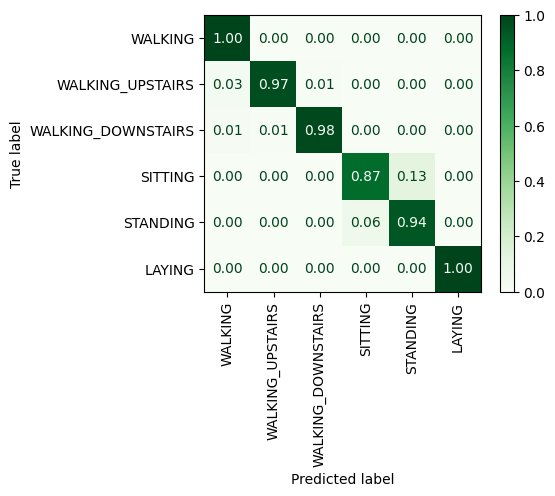

In [12]:
y_true = np.argmax(dataset["test"]["label"], axis=1)
y_pred = predict_labels(model, dataset["test"]["data"], mode="MTL")
report(y_true, y_pred, dataset["labels"])
plot_confusion_matrix(y_true, y_pred, dataset["labels"], show=True);

## 4. Signal reconstruction

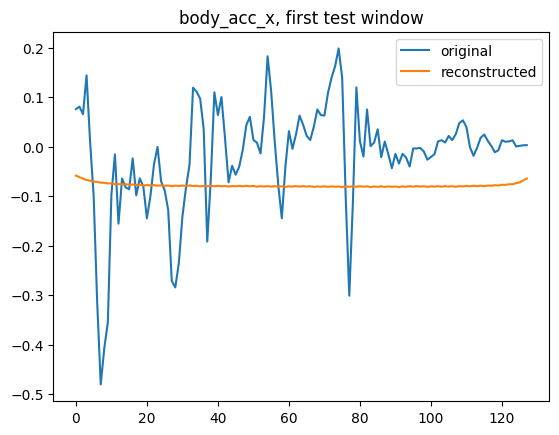

In [12]:
import matplotlib.pyplot as plt

reconstruction, _ = model.predict(dataset["test"]["data"][:1], verbose=0)
channel = 0
plt.plot(dataset["test"]["data"][0, :, channel], label="original")
plt.plot(reconstruction[0, :, channel], label="reconstructed")
plt.legend(); plt.title("body_acc_x, first test window"); plt.show()

# Train with the classifier mode

In [3]:
hp = HParams(epochs=10)  # increase epochs for better results
model, history = train(dataset, hp, mode="classifier")

Shape the data (5881, 128, 10) (5881, 6) (1471, 128, 10) (1471, 6)


Model: "mtl_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ encoder (Functional)                 │ ?                           │          17,730 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ classifier (Functional)              │ ?                           │             206 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 17,936 (70.06 KB)

 Trainable params: 17,876 (69.83 KB)

 Non-trainable params: 60 (240.00 B)

Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 48ms/step - accuracy: 0.5175 - loss: 1.5665 - val_accuracy: 0.8790 - val_loss: 0.5259
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9089 - loss: 0.4736 - val_accuracy: 0.9456 - val_loss: 0.3531
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9414 - loss: 0.3431 - val_accuracy: 0.9490 - val_loss: 0.3193
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9511 - loss: 0.3074 - val_accuracy: 0.9551 - val_loss: 0.2979
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9566 - loss: 0.2873 - val_accuracy: 0.9572 - val_loss: 0.2798
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9595 - loss: 0.2718 - val_accuracy: 0.9606 - val_loss: 0.2645
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9623 - loss: 0.2569 - val_accuracy: 0.9660 - val_loss: 0.2510
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9640 - loss: 0.2432 - val_accuracy: 0.9660 - 

                    precision    recall  f1-score   support

           WALKING      0.971     0.998     0.984       496
  WALKING_UPSTAIRS      0.991     0.968     0.980       471
WALKING_DOWNSTAIRS      0.993     0.986     0.989       420
           SITTING      0.929     0.878     0.903       491
          STANDING      0.891     0.936     0.913       532
            LAYING      1.000     1.000     1.000       537

          accuracy                          0.961      2947
         macro avg      0.962     0.961     0.961      2947
      weighted avg      0.961     0.961     0.961      2947



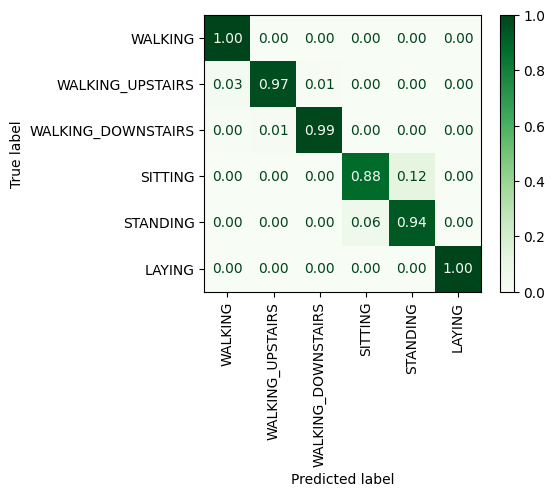

In [8]:
y_true = np.argmax(dataset["test"]["label"], axis=1)
y_pred = predict_labels(model, dataset["test"]["data"], mode="classifier")
report(y_true, y_pred, dataset["labels"])
plot_confusion_matrix(y_true, y_pred, dataset["labels"], show=True);

# Train with the Autoencoder mode

In [9]:
hp = HParams(epochs=10)  # increase epochs for better results
model, history = train(dataset, hp, mode="AE")

Shape the data (5881, 128, 10) (5881, 6) (1471, 128, 10) (1471, 6)


Model: "mtl_model_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ encoder (Functional)                 │ ?                           │          17,730 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ decoder (Functional)                 │ ?                           │          20,930 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 38,660 (151.02 KB)

 Trainable params: 38,620 (150.86 KB)

 Non-trainable params: 40 (160.00 B)

Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 31s 82ms/step - loss: 4.4105 - rmse: 0.7615 - val_loss: 3.1148 - val_rmse: 0.7099
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 2.8153 - rmse: 0.7155 - val_loss: 2.0428 - val_rmse: 0.7034
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 1.8562 - rmse: 0.7014 - val_loss: 1.3522 - val_rmse: 0.6574
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 1.2359 - rmse: 0.6554 - val_loss: 0.9254 - val_rmse: 0.6322
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.8585 - rmse: 0.6410 - val_loss: 0.6682 - val_rmse: 0.6292
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.6300 - rmse: 0.6385 - val_loss: 0.5124 - val_rmse: 0.6278
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.4919 - rmse: 0.6370 - val_loss: 0.4189 - val_rmse: 0.6268
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.4092 - rmse: 0.6360 - val_loss: 0.3633 - val_rmse: 0.6253
Epoch 9/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/s

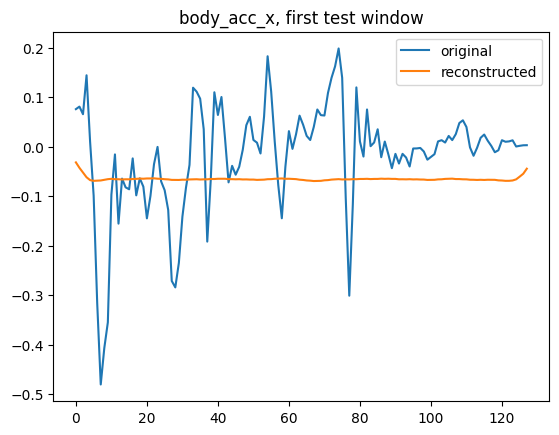

In [10]:
import matplotlib.pyplot as plt

reconstruction = model.predict(dataset["test"]["data"][:1], verbose=0)
channel = 0
plt.plot(dataset["test"]["data"][0, :, channel], label="original")
plt.plot(reconstruction[0, :, channel], label="reconstructed")
plt.legend(); plt.title("body_acc_x, first test window"); plt.show()